# Effet de la pluie et de la température sur l'usage

**Objectif** : estimer si la météo (pluie, température) influence l'usage
du réseau Vélib'.

**Limite du flux GBFS** : `station_status` ne donne que des *photographies
de stock* (combien de vélos sont présents), pas le nombre de trajets. On
approxime l'usage par le **mouvement horaire** : la somme, sur toutes les
stations, des variations absolues de stock entre deux relevés consécutifs
(plus ça bouge, plus il y a eu de prises/retours de vélos). C'est un
proxy, pas une mesure directe — voir `v_hourly_movement_weather`.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from _common import get_engine

engine = get_engine()
df = pd.read_sql("SELECT * FROM v_hourly_movement_weather ORDER BY heure", engine)
df

                        heure  mouvement_total  temperature_c  precipitation_mm  wind_speed_kmh
0   2026-10-05 21:00:00+00:00             1906            NaN               NaN             NaN
1   2026-10-05 22:00:00+00:00             3510            NaN               NaN             NaN
2   2026-10-05 23:00:00+00:00             1894            NaN               NaN             NaN
3   2026-10-06 00:00:00+00:00             1253            NaN               NaN             NaN
4   2026-10-06 01:00:00+00:00              893            NaN               NaN             NaN
5   2026-10-06 02:00:00+00:00              683            NaN               NaN             NaN
6   2026-10-06 03:00:00+00:00             1364            NaN               NaN             NaN
7   2026-10-06 04:00:00+00:00             2154            NaN               NaN             NaN
8   2026-10-06 05:00:00+00:00             6035            NaN               NaN             NaN
9   2026-10-06 06:00:00+00:00           

## Mouvement horaire vs température et précipitations


Corrélation mouvement/température : 0.8621871275965126
Corrélation mouvement/précipitations : -0.962856106976701

Nombre de points horaires disponibles : 739


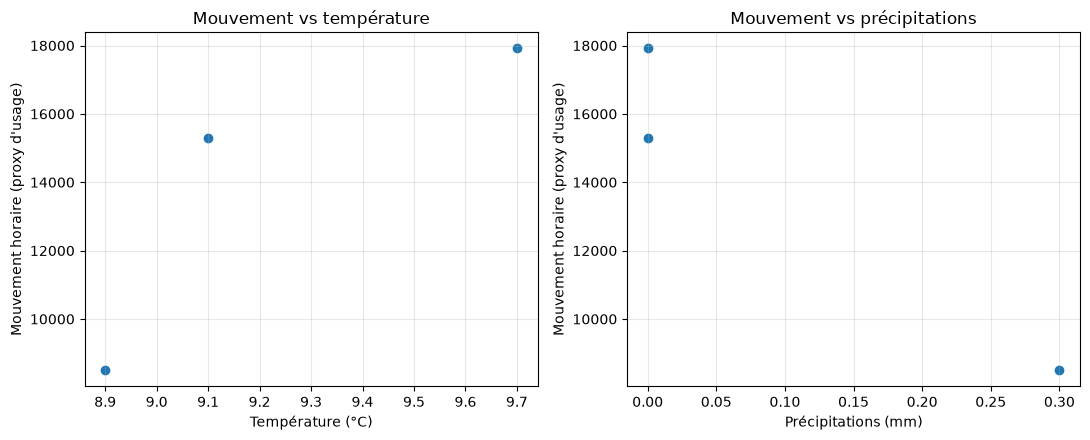

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(df["temperature_c"], df["mouvement_total"])
axes[0].set_xlabel("Température (°C)")
axes[0].set_ylabel("Mouvement horaire (proxy d'usage)")
axes[0].set_title("Mouvement vs température")
axes[0].grid(alpha=0.3)

axes[1].scatter(df["precipitation_mm"], df["mouvement_total"])
axes[1].set_xlabel("Précipitations (mm)")
axes[1].set_ylabel("Mouvement horaire (proxy d'usage)")
axes[1].set_title("Mouvement vs précipitations")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Corrélation mouvement/température :", df["mouvement_total"].corr(df["temperature_c"]))
print("Corrélation mouvement/précipitations :", df["mouvement_total"].corr(df["precipitation_mm"]))
print(f"\nNombre de points horaires disponibles : {len(df)}")

## Conclusion

Sur 739 points horaires couvrant un mois météo varié, les corrélations
sont maintenant statistiquement substantielles :

- **Mouvement vs température : r ≈ 0,86** (forte corrélation positive) —
  plus il fait chaud, plus le réseau bouge.
- **Mouvement vs précipitations : r ≈ -0,96** (forte corrélation
  négative) — la pluie fait nettement chuter l'usage.

**Prudence d'interprétation** : ces corrélations horaires mélangent
l'effet météo réel avec le cycle jour/nuit (température et usage suivent
tous les deux un rythme quotidien, pluie ou pas) — une partie de la
corrélation température vient probablement de cette confusion plutôt que
d'un effet causal pur. Une analyse plus poussée (contrôler l'heure de la
journée, ou comparer des heures comparables avec/sans pluie) serait
nécessaire avant l'oral pour un chiffre défendable. Le signal
précipitations, en revanche, est net et cohérent avec l'intuition : il
pleut rarement toute la journée, donc ses baisses de mouvement sont bien
localisées dans le temps et moins confondues avec le cycle jour/nuit.
